# Import bibliotek

In [1]:
import numpy as np
import pandas as pd
import sklearn as sl
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score

In [2]:
print(f'NumPy: {np.__version__}')
print(f'Pandas: {pd.__version__}')
print(f'Sklearn: {sl.__version__}')
print(f'Matplotlib: {mpl.__version__}')
print(f'Seaborn: {sns.__version__}')

NumPy: 2.2.6
Pandas: 2.3.3
Sklearn: 1.7.2
Matplotlib: 3.11.2
Seaborn: 0.13.2


# Ładownie zbioru danych

In [3]:
df = sns.load_dataset('iris')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
def color_brew(n):
    """Generate n colors with equally spaced hues.

    Parameters
    ----------
    n : int
        The number of colors required.

    Returns
    -------
    color_list : list, length n
        List of n tuples of form (R, G, B) being the components of each color.
    """
    color_list = []

    # Initialize saturation & value; calculate chroma & value shift
    s, v = 0.75, 0.9
    c = s * v
    m = v - c

    for h in np.arange(25, 385, 360.0 / n).astype(int):
        # Calculate some intermediate values
        h_bar = h / 60.0
        x = c * (1 - abs((h_bar % 2) - 1))
        # Initialize RGB with same hue & chroma as our color
        rgb = [
            (c, x, 0),
            (x, c, 0),
            (0, c, x),
            (0, x, c),
            (x, 0, c),
            (c, 0, x),
            (c, x, 0),
        ]
        r, g, b = rgb[int(h_bar)]
        # Shift the initial RGB values to match value and store
        rgb = ((int(255 * (r + m))), (int(255 * (g + m))), (int(255 * (b + m))))
        color_list.append('#%02x%02x%02x' % rgb)

    return color_list

# EDA

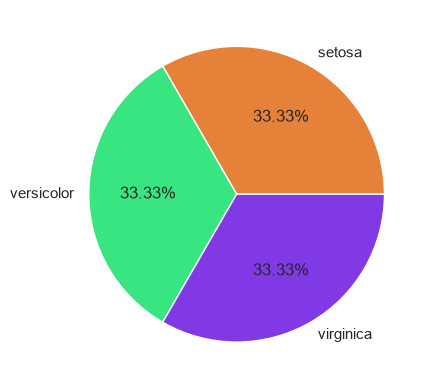

In [5]:
nc = len(df['species'].unique())
g = df.groupby('species').size().reset_index()
plt.pie(g[0], labels=g['species'], autopct='%.2f%%', colors=sns.color_palette(color_brew(nc), nc));

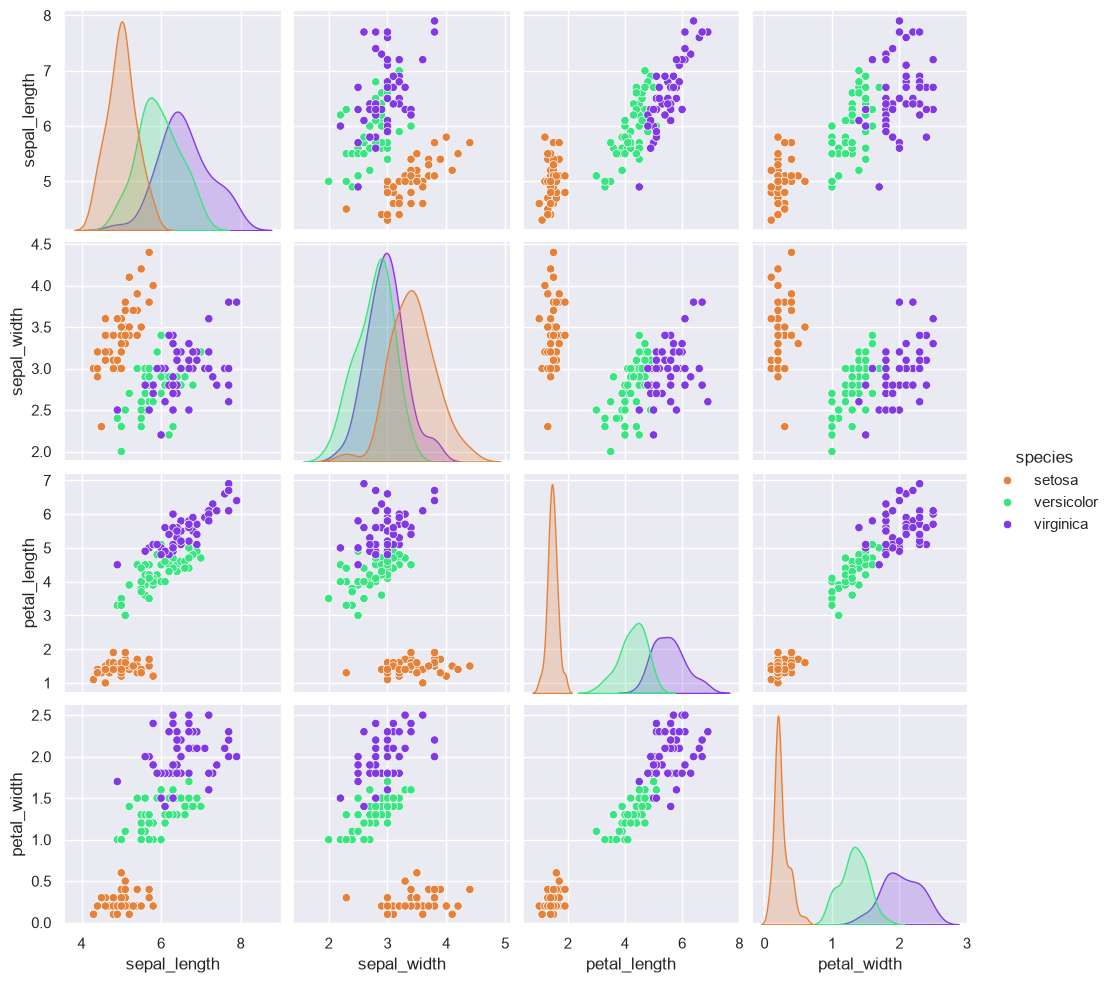

In [6]:
sns.pairplot(df, hue='species', palette=sns.color_palette(color_brew(nc), nc));

# Trenowanie modelu

In [7]:
X = df.drop(columns='species')
y = df['species']
X.shape, y.shape

((150, 4), (150,))

In [8]:
dt = DecisionTreeClassifier()
dt.fit(X, y)
dt.score(X, y)

1.0

In [9]:
sns.reset_orig()
plt.figure(figsize=(12, 12))
plot_tree(dt, feature_names=list(X.columns), class_names=y.unique(), filled=True, rounded=True)
sns.set()

In [10]:
dt.get_depth()

5

# Dostrajanie modelu

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((105, 4), (45, 4), (105,), (45,))

In [12]:
dt1 = DecisionTreeClassifier()
dt1.fit(X_train, y_train)
dt1.score(X_train, y_train), dt1.score(X_test, y_test)

(1.0, 0.9333333333333333)

In [13]:
scores = {}
for depth in range(1, 10):
  dt_x = DecisionTreeClassifier(max_depth=depth, random_state=42)
  dt_x.fit(X_train, y_train)
  scores[depth] = dt_x.score(X_train, y_train), dt_x.score(X_test, y_test)
scores

{1: (0.6666666666666666, 0.6666666666666666),
 2: (0.9619047619047619, 0.9333333333333333),
 3: (0.9714285714285714, 0.9555555555555556),
 4: (1.0, 0.9333333333333333),
 5: (1.0, 0.9333333333333333),
 6: (1.0, 0.9333333333333333),
 7: (1.0, 0.9333333333333333),
 8: (1.0, 0.9333333333333333),
 9: (1.0, 0.9333333333333333)}

# Walidacja krzyżowa

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=54)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

In [15]:
dt2 = DecisionTreeClassifier(max_depth=3, random_state=42)
scores = cross_val_score(dt2, X_train, y_train, cv=5)
scores

array([0.91666667, 0.95833333, 0.91666667, 0.875     , 1.        ])

In [16]:
scores.mean(), scores.std()

(np.float64(0.9333333333333332), np.float64(0.042491829279939886))

# Optymalna glebokosc drzewa - walidacja krzyzowa

In [17]:
wyniki_cv = {}
for depth in range(1, 10):
  dt_x = DecisionTreeClassifier(max_depth=depth, random_state=42)
  s = cross_val_score(dt_x, X_train, y_train, cv=5)
  wyniki_cv[depth] = s.mean(), s.std()

wyniki_cv = pd.DataFrame(wyniki_cv, index=['srednia', 'odch. std']).T
wyniki_cv

,srednia,odch. std
1,0.666667,0.000000
2,0.941667,0.020412
3,0.933333,0.042492
4,0.933333,0.050000
5,0.941667,0.042492
6,0.941667,0.042492
7,0.941667,0.042492
8,0.941667,0.042492
9,0.941667,0.042492


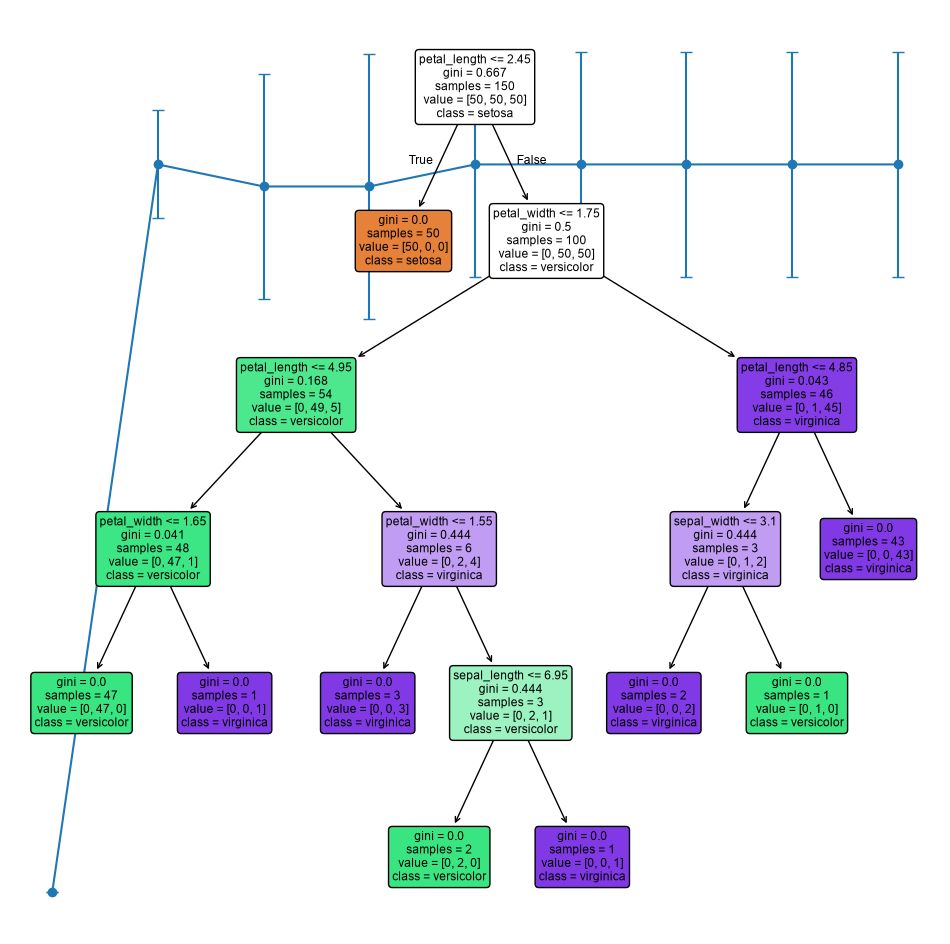

In [18]:
plt.errorbar(wyniki_cv.index, wyniki_cv['srednia'], yerr=wyniki_cv['odch. std'], marker='o', capsize=4)
plt.xlabel('max_depth')
plt.ylabel('dokladnosc (walidacja krzyzowa)')
plt.show()

In [19]:
best_depth = wyniki_cv['srednia'].idxmax()
print('optymalna glebokosc =', best_depth)

dt_best = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_best.fit(X_train, y_train)
dt_best.score(X_train, y_train), dt_best.score(X_test, y_test)

optymalna glebokosc = 2


(0.9666666666666667, 0.9333333333333333)

Komentarz

Najlepsza srednia dokladnosc w walidacji krzyzowej (0.94) daje juz glebokosc 2 - glebsze drzewa nie sa lepsze, a glebokosc 2 ma najmniejszy rozrzut (std 0.02) i jest najprostsza, wiec ja wybieramy. Na zbiorze testowym drzewo o glebokosci 2 ma dokladnosc 0.93.